# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [4]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [5]:
x = np.arange(7,8,0.001)   #dummy range for function - creates an array of evenly spaced numbers within a [7.0,8.0]
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [6]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi,x)] # f(x) calculated on specific dataset x_i inside discrete intervals (bins) of x in [7.0,8.0]

#######################################
print("Data Preparation:\n")
#print("Numbers within [7.0,8.0] are in array x=\n", x)
#print("f(x) in [7.0,8.0] has values in array y=\n", y)
print("Interpolation points are: x_i=", xi, "\n")
x_dig_idx = np.digitize(xi,x)
print("indices (from np.digitize) on interpolation points of x in [7.0,8.0]=", x_dig_idx, "\n")
for idx in x_dig_idx:
    print(f"x[{idx}]={x[idx]} ")
print("\nf(x) values on above interpolation points of x in [7.0,8.0] are: y_i=", yi, "\n")
print ("#######################################\n")

Data Preparation:

Interpolation points are: x_i= [7.2 7.4 7.6 7.8] 

indices (from np.digitize) on interpolation points of x in [7.0,8.0]= [200 400 600 800] 

x[200]=7.200000000000067 
x[400]=7.400000000000134 
x[600]=7.6000000000002 
x[800]=7.800000000000267 

f(x) values on above interpolation points of x in [7.0,8.0] are: y_i= [21.04501699 21.09498301 22.29498301 24.64501699] 

#######################################



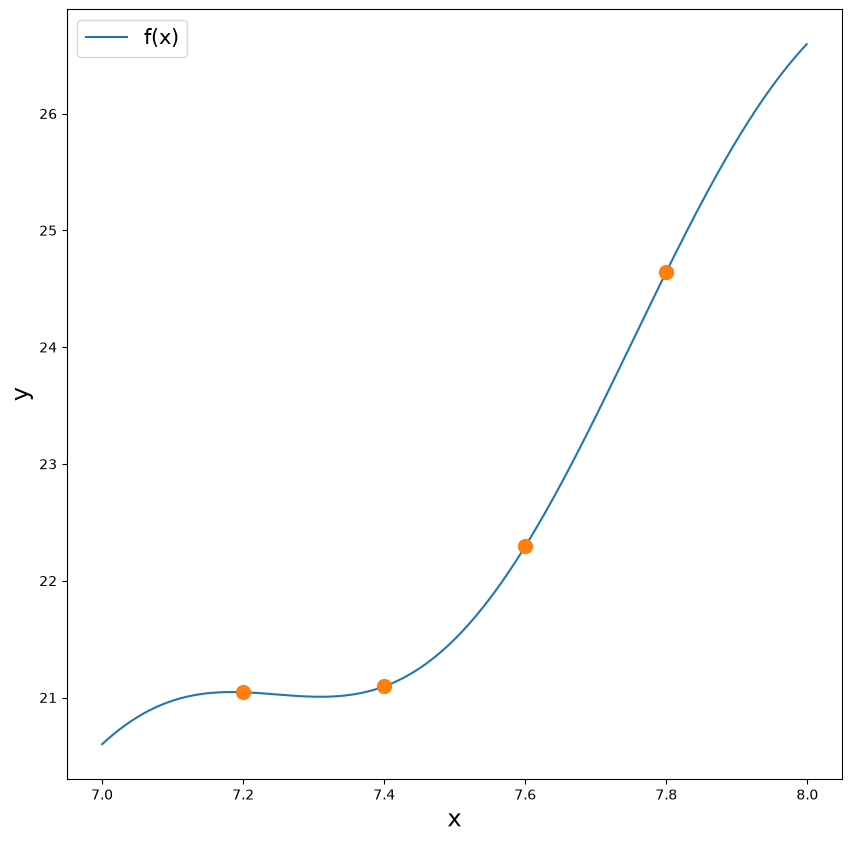

In [7]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)')  
plt.plot(xi,yi,'o',markersize=10)
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)


--- Error Bound Analysis ---
Max |f''''(xi)| over [7.2, 7.8]: 1558.5455
Max |omega(x)| over [7.2, 7.8]:  0.001600
Estimated Max Absolute Error Bound: 0.103901


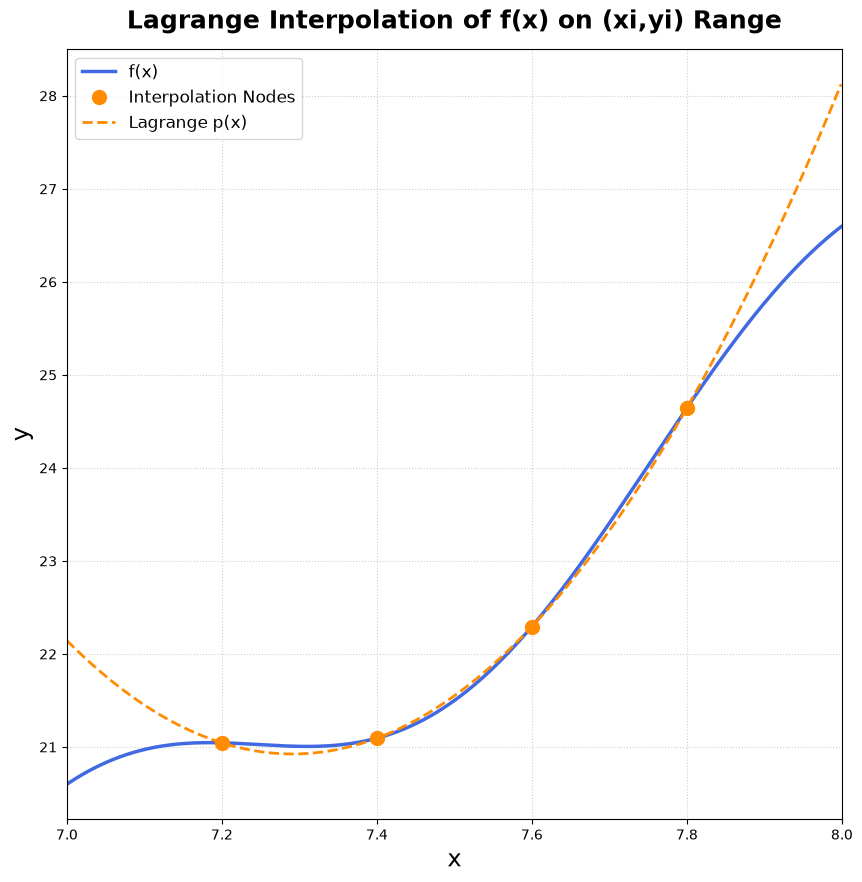

In [8]:
# --- Part A: Lagrange Polynomial Function ---
# Lagrange polynomial fits a single polynomial curve through a fixed set of data points
# Function Parameters:
#    x_val: The target x-coordinate we want to interpolate.
#    x_nodes: The x-coordinates of the known data points.
#    y_nodes: The y-coordinates of the known data points.
# Returns:
#    float: The interpolated y-value corresponding to x_val.
def lagrange_interpolation(x_val, x_nodes, y_nodes):
    n = len(x_nodes) # Determine the total number of known data points used for calculation
    p = 0.0
    for i in range(n):
        L = 1.0
        for j in range(n):
            if i != j: ## Skip the term where i == j to avoid division by zero (x_node[i] - x_node[i])
                fraction = (x_val - x_nodes[j]) / (x_nodes[i] - x_nodes[j]) # Calculate the fraction: (x - x_j) / (x_i - x_j)
                L = L * fraction #  Multiply the fraction into the running product for L_i(x)
        p = p + y_nodes[i] * L # Add the weighted contribution (y_i * L_i(x)) to the total p
    return p # final aggregated interpolated value

# Compute the polynomial p(x) over the entire array range [7.0,8.0] for plotting
y_lagrange = np.zeros(len(x))
for i in range(len(x)):
    # Extract the specific 'x' value at the current index position
    val = x[i]
    # Calculate the Lagrange value for this specific point
    y_lagrange[i] = lagrange_interpolation(val, xi, yi)
#    print(f"for x val = {x[i]} we have calculated lagrange value: {y_lagrange[i]}")

# Estimate Maximum Absolute Error Boundary
# Interval for epsilon is [x_0, x_n] -> [7.2, 7.8] (interplation interval is inside [7.0,8.0] - dummy range for function)
# Locate the integer index boundaries where x crosses xi[0] and xi[-1] (first and last element of array xi)
start_idx = 0
for i in range(len(x)):
    if x[i] >= xi[0]:
        start_idx = i
        break  
end_idx = 0
for i in range(len(x)):
    if x[i] <= xi[-1]:
        end_idx = i + 1  
# Extract data in our interpolation interval [7.2, 7.8] using start/end index boundaries
x_interval = x[start_idx:end_idx]

#  Max absolute 4th derivative Max_f4 = max |16 * pi^4 * cos(-2 * pi * x)| in x_interval (inside [7.2, 7.8])
f4_derivative = 16 * (np.pi**4) * np.cos(-2 * np.pi * x_interval)
max_f4 = np.max(np.abs(f4_derivative))

# Max absolute value of the  omega(x) = (x-7.2)(x-7.4)(x-7.6)(x-7.8)
omega = (x_interval - xi[0]) * (x_interval - xi[1]) * (x_interval - xi[2]) * (x_interval - xi[3])
max_omega = np.max(np.abs(omega))

# Calculate Error Boundary = (Max_f4 / 4!) * max|omega(x)|
error_bound = (max_f4 / 24.0) * max_omega

print("--- Error Bound Analysis ---")
print(f"Max |f''''(xi)| over [7.2, 7.8]: {max_f4:.4f}")
print(f"Max |omega(x)| over [7.2, 7.8]:  {max_omega:.6f}")
print(f"Estimated Max Absolute Error Bound: {error_bound:.6f}")

# --- Combined Plot Construction ---
plt.figure(figsize=(10, 10))
plt.plot(x, y, label='f(x)', color='royalblue', linewidth=2.5)  
plt.plot(xi, yi, 'o', markersize=10, color='darkorange', label='Interpolation Nodes')

# Overlaying the calculated Lagrange polynomial p(x)
plt.plot(x, y_lagrange, label='Lagrange p(x)', color='darkorange', linestyle='--', linewidth=2)

# Formatting elements
plt.xlabel('x', fontsize=17)
plt.ylabel('y', fontsize=17)
plt.title('Lagrange Interpolation of f(x) on (xi,yi) Range', fontsize=18, fontweight='bold', pad=15)
plt.xlim(7.0, 8.0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='best', fontsize=12)

plt.show()

##  The Lagrange interpolating polynomial 
is weighted linear combination of the given $y$-values:

$$P_{n}(x)=\sum _{i=0}^{n}y_{i}\cdot L_{i}(x)$$

Where $L_i(x)$ is called the Lagrange basis polynomial corresponding to the node $x_{i}$.


## Time Complexity
The time complexity of this function is O(n^2), where n is the number of data points (`x_nodes`).
We have in program 2 nested loops in relation to \(n\):
1. Outer Loop (for i in range(n)):
   This loop runs exactly \(n\) times — once for each known data point.
2. Inner Loop (for j in range(n)):
   Inside the outer loop, this inner loop also tries to run \(n\) times for every single iteration of i.
3. Core Operation (if i != j). It runs \(n-1\) times for each outer loop (it skips one time when \(i = j\)).

Total number of operations is multiplication of the iterations of the outer loop by the iterations of the inner loop:

Total Operations ~ n * (n-1)=n^2-n;  For very big n we can assume: O(n^2)


## Estimating the Maximum Absolute Error Boundary

For $n+1 = 4$ nodes, the Lagrange error formula gives for $x \in [7.2, 7.8]$:

$$|E(x)| = |f(x)-p(x)| = \frac{|f^{(4)}(\xi)|}{4!} |\omega(x)|$$

### 1. Maximum of Fourth Derivative of f(x) ($Maxf_{4}$)
Differentiating $f(x) = \cos(-2\pi x) + 0.4x^2$ four times gives the function:

$$f^{(4)}(x)=16\pi ^{4}\cos (-2\pi x)$$

Because $|\cos(\theta)| \le 1$, the limit of the derivation is $16\pi^4 \approx \mathbf{1558.5427}$.

### 2. Omega ($\max|\omega(x)|$)

$\omega(x)$ represents the product of the distance from any evaluation point $x$ to each of the interpolation nodes:

$$\omega (x)=\prod _{i=0}^{n}(x-x_{i})=(x-x_{0})(x-x_{1})\cdots (x-x_{n})$$

With evaluating $\omega(x) = (x-7.2)(x-7.4)(x-7.6)(x-7.8)$ over the boundaries with the following python code: 

 "omega = (x_interval - xi[0]) * (x_interval - xi[1]) * (x_interval - xi[2]) * (x_interval - xi[3])" and "max_omega = np.max(np.abs(omega))"
 
we have a maximum absolute value of roughly $\mathbf{0.001600}$.

### 3. Total Error Boundary is approx.:
$$\text{Error Bound} \le \frac{1558.5427}{24} \times 0.001600 \approx \mathbf{0.103903}$$


----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?

METRICS FOR PLOT 1 (Calculated Step Size)
Calculated required step size d     : 0.00004353
Number of discrete intervals needed : 45948
Verified actual maximum error       : 6.80e-07


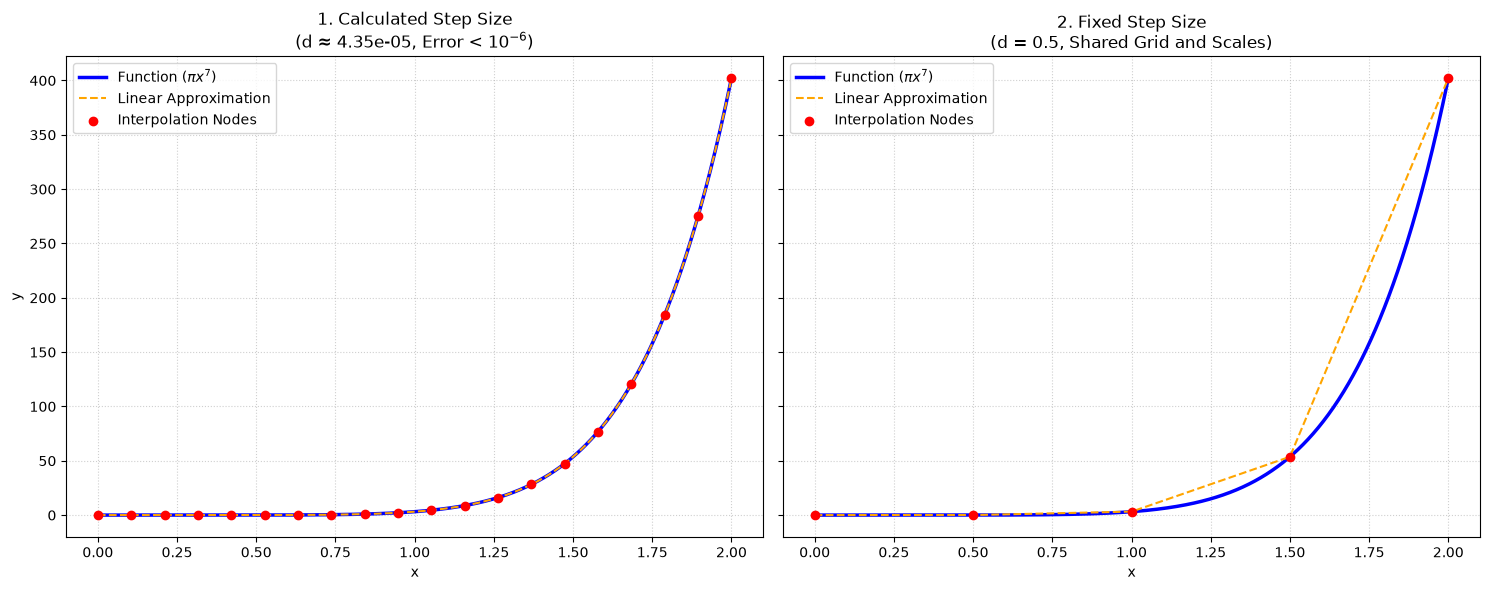

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the mathematical function
def y_func(x):
    return np.pi * (x**7)

X_min, X_max = 0.0, 2.0
E_max = 1e-6

# Generate high-resolution grid for plotting and error evaluation
x_fine = np.linspace(X_min, X_max, 1000)
y_true_fine = y_func(x_fine)

# =========================================================================
# CONFIGURATION FOR PLOT 1: Calculated Step Size (Error < 10^-6)
# =========================================================================
# The second derivative is y''(x) = 42 * pi * x^5, which peaks at x = 2
max_y_double_prime = 42 * np.pi * (X_max**5)
d_calculated = np.sqrt((8 * E_max) / max_y_double_prime)

# Generate nodes for Plot 1
num_intervals_1 = int(np.ceil((X_max - X_min) / d_calculated))
x_nodes_1 = np.linspace(X_min, X_max, num_intervals_1 + 1)
y_nodes_1 = y_func(x_nodes_1)
y_interp_1 = np.interp(x_fine, x_nodes_1, y_nodes_1)

# Calculate verified actual maximum error for Plot 1
actual_error_1 = np.max(np.abs(y_true_fine - y_interp_1))

# =========================================================================
# PRINT METRICS STATEMENTS (As requested)
# =========================================================================
print("=" * 50)
print("METRICS FOR PLOT 1 (Calculated Step Size)")
print("=" * 50)
print(f"Calculated required step size d     : {d_calculated:.8f}")
print(f"Number of discrete intervals needed : {num_intervals_1}")
print(f"Verified actual maximum error       : {actual_error_1:.2e}")
print("=" * 50)

# =========================================================================
# CONFIGURATION FOR PLOT 2: Fixed Step Size (d = 0.5)
# =========================================================================
d_fixed = 0.5

# Generate nodes (Points at 0.0, 0.5, 1.0, 1.5, 2.0)
num_intervals_2 = int((X_max - X_min) / d_fixed)
x_nodes_2 = np.linspace(X_min, X_max, num_intervals_2 + 1)
y_nodes_2 = y_func(x_nodes_2)
y_interp_2 = np.interp(x_fine, x_nodes_2, y_nodes_2)

# =========================================================================
# GENERATE SUBPLOTS WITH SHARED AXES/GRID
# =========================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

# --- PLOT 1 ---
ax1.plot(x_fine, y_true_fine, label=r"Function ($\pi x^7$)", color="blue", linewidth=2.5)
ax1.plot(x_fine, y_interp_1, label="Linear Approximation", color="orange", linestyle="--", linewidth=1.5)
sparse_indices = np.linspace(0, len(x_nodes_1)-1, 20, dtype=int)
ax1.scatter(x_nodes_1[sparse_indices], y_nodes_1[sparse_indices], color="red", zorder=3, label="Interpolation Nodes")

ax1.set_title(f"1. Calculated Step Size\n(d ≈ {d_calculated:.2e}, Error < $10^{{-6}}$)", fontsize=12)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# --- PLOT 2 ---
ax2.plot(x_fine, y_true_fine, label=r"Function ($\pi x^7$)", color="blue", linewidth=2.5)
ax2.plot(x_fine, y_interp_2, label="Linear Approximation", color="orange", linestyle="--", linewidth=1.5)
ax2.scatter(x_nodes_2, y_nodes_2, color="red", zorder=3, label="Interpolation Nodes")

ax2.set_title("2. Fixed Step Size\n(d = 0.5, Shared Grid and Scales)", fontsize=12)
ax2.set_xlabel("x")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

----------------------------------------------------------

## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

Text(0, 0.5, 'y')

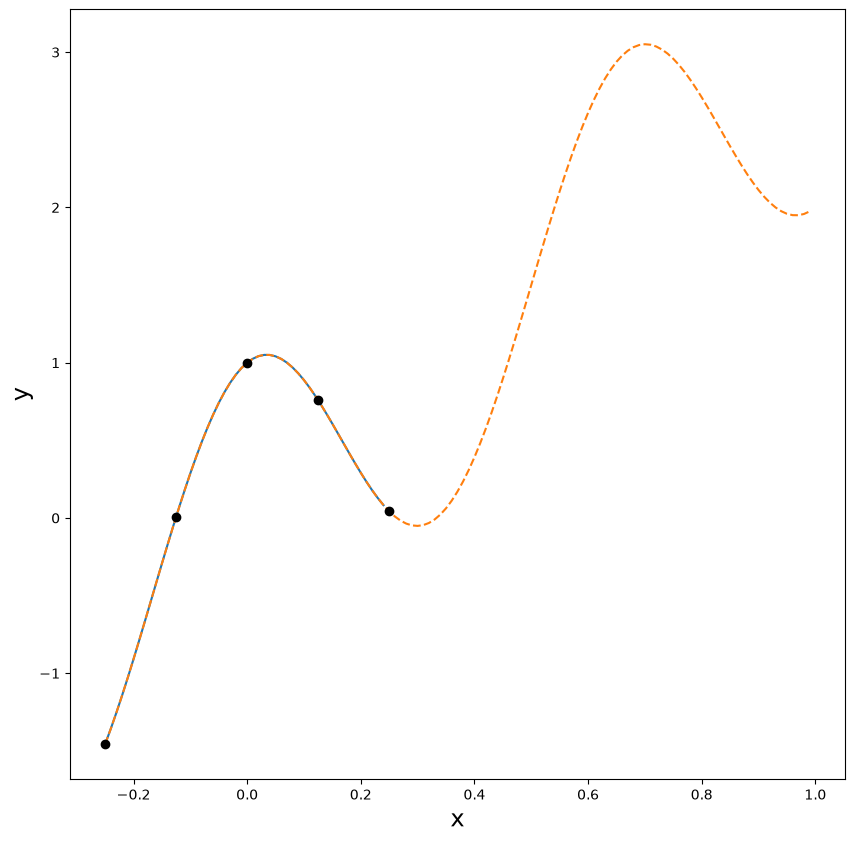

In [44]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi
plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)

----------------------------------------------------------

--- Automated Order Identification ---
Required order j found programmatically: 14
Maximum absolute error on xdum with order 14: 4.2357e-08

--- Taylor Polynomial Approximation Evaluation (j = 14) ---
At x = -0.250:
  Exact y         =    -1.45710678
  Taylor Approx   =    -1.45710682
  Absolute Error  =       4.24e-08
At x = -0.125:
  Exact y         =     0.00768343
  Taylor Approx   =     0.00768343
  Absolute Error  =       6.55e-13
At x =  0.000:
  Exact y         =     1.00000000
  Taylor Approx   =     1.00000000
  Absolute Error  =       0.00e+00
At x =  0.125:
  Exact y         =     0.75768343
  Taylor Approx   =     0.75768343
  Absolute Error  =       6.55e-13
At x =  0.250:
  Exact y         =     0.04289322
  Taylor Approx   =     0.04289318
  Absolute Error  =       4.24e-08
------------------------------------------------------------


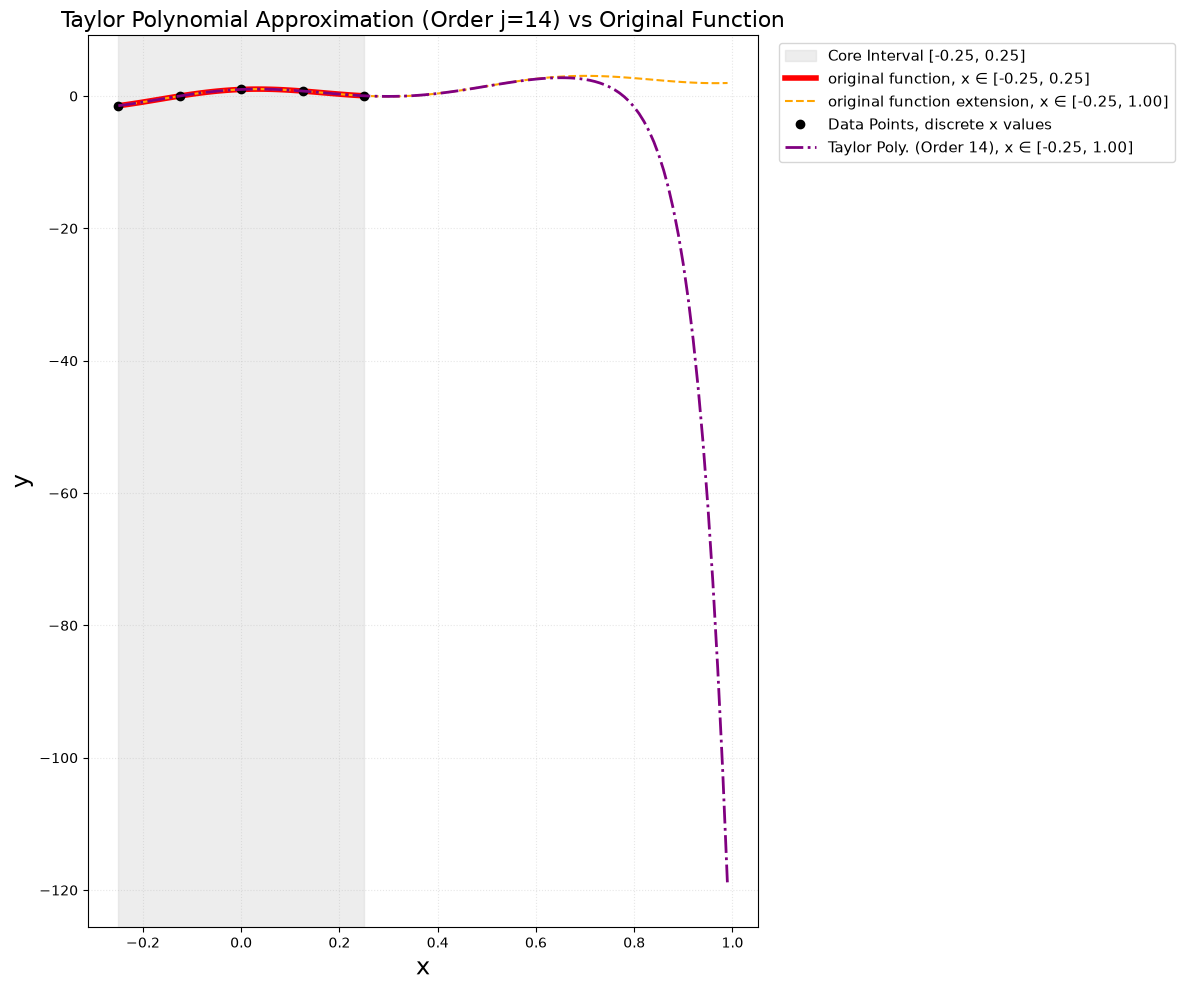

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Provided Python statements
xi = np.arange(-0.25, 1, 0.01)
xdum = np.arange(-0.25, 0.25, 0.01)
x = np.array([-0.25, -0.125, 0, 0.125, 0.25])
y = np.cos(-3 * np.pi * x) + 3 * x
ydum = np.cos(-3 * np.pi * xdum) + 3 * xdum
yi = np.cos(-3 * np.pi * xi) + 3 * xi

# Define the Taylor Polynomial function centered at x = 0
def taylor_cos_plus_3x(x_val, order):
    t_poly = 3 * x_val 
    u = 3 * np.pi * x_val
    for k in range(order + 1):
        if k % 2 == 0:
            sign = (-1) ** (k // 2)
            term = sign * (u ** k) / math.factorial(k)
            t_poly += term
    return t_poly

# --- Programmatic calculation of required order j ---
error_threshold = 1e-6
j = 1  # Start at order 1

while True:
    y_approx_check = taylor_cos_plus_3x(xdum, j)
    max_absolute_error = np.max(np.abs(ydum - y_approx_check))
    
    if max_absolute_error < error_threshold:
        break
    j += 1

print(f"--- Automated Order Identification ---")
print(f"Required order j found programmatically: {j}")
print(f"Maximum absolute error on xdum with order {j}: {max_absolute_error:.4e}\n")


# Compute Taylor approximations using the dynamically solved order j
y_taylor_xdum = taylor_cos_plus_3x(xdum, j)
y_taylor_xi = taylor_cos_plus_3x(xi, j)

# --- Print Section for Data Points ---
print(f"--- Taylor Polynomial Approximation Evaluation (j = {j}) ---")
y_taylor_discrete = taylor_cos_plus_3x(x, j)
abs_errors = np.abs(y - y_taylor_discrete)

for idx in range(len(x)):
    print(f"At x = {x[idx]:6.3f}:")
    print(f"  Exact y         = {y[idx]:14.8f}")
    print(f"  Taylor Approx   = {y_taylor_discrete[idx]:14.8f}")
    print(f"  Absolute Error  = {abs_errors[idx]:14.2e}")
print("-" * 60)

# Plotting setup
plt.figure(figsize=(12, 10))

# --- Shade the Core Interval Region ---
plt.axvspan(-0.25, 0.25, color='lightgray', alpha=0.4, label='Core Interval [-0.25, 0.25]')

# Plots with explicit intervals of validity added to the labels
plt.plot(xdum, ydum, label='original function, x ∈ [-0.25, 0.25]', color='red', linewidth=4)
plt.plot(xi, yi, '--', label='original function extension, x ∈ [-0.25, 1.00]', color='orange')
plt.plot(x, y, 'o', c='black', label='Data Points, discrete x values')

# Adding the Taylor Polynomial approximation plots with intervals
###plt.plot(xdum, y_taylor_xdum, ':', label=f'Taylor Poly. (Order {j}), x ∈ [-0.25, 0.25]', color='red', linewidth=3)
plt.plot(xi, y_taylor_xi, '-.', label=f'Taylor Poly. (Order {j}), x ∈ [-0.25, 1.00]', color='purple', linewidth=2)

# Labels and title
plt.xlabel('x', fontsize=17)
plt.ylabel('y', fontsize=17)
plt.title(f'Taylor Polynomial Approximation (Order j={j}) vs Original Function', fontsize=16)
plt.grid(True, linestyle=':', alpha=0.3)

# Move the legend outside of the plot area (to the right side)
plt.legend(fontsize=11, bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust layout so everything fits without clipping
plt.tight_layout()
plt.show()

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


Text(0.2190020868382998, 0.20315260898536833, '($x_r,y_r)$')

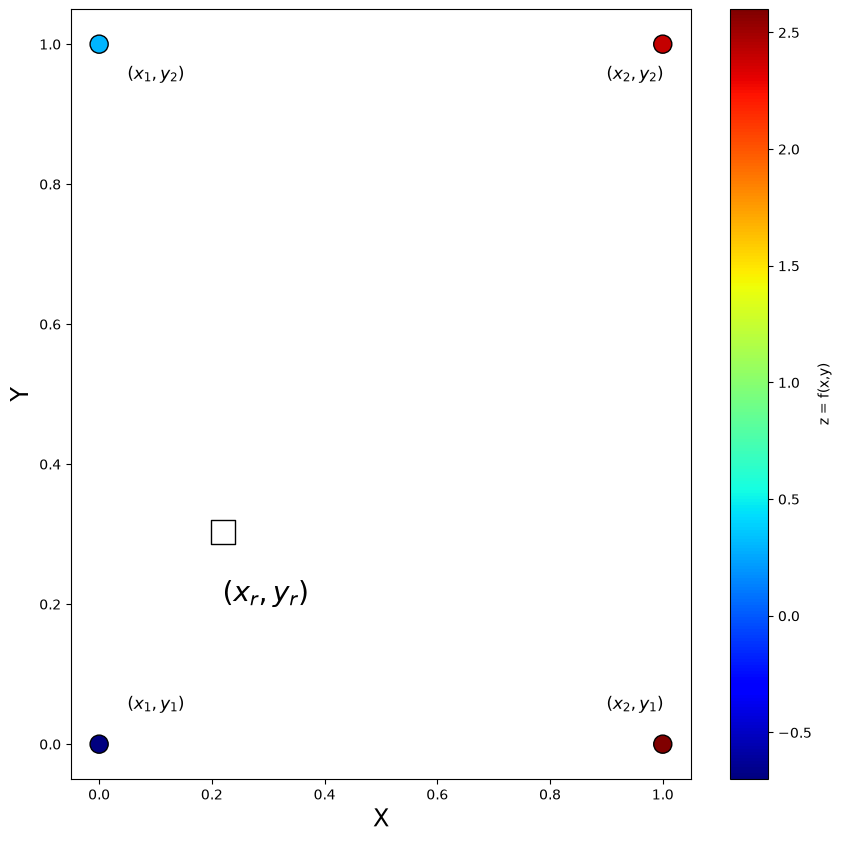

In [46]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

#Visualize
plt.figure(figsize=(10,10))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black')
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)
plt.scatter(xr,yr,edgecolor='black',marker='s',s=290,c='white')
plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)

Random Point: (0.7568, 0.5028)
Interpolated Value z_r: 1.8436


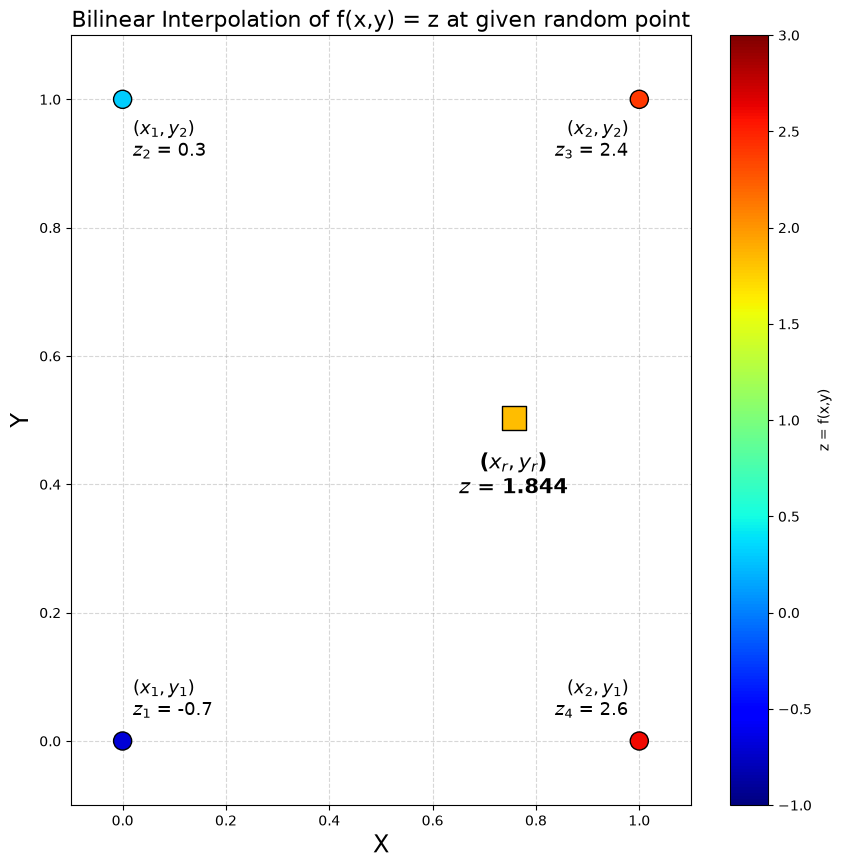

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# --- Your exact provided statements ---
# Known data points and function values are provided in following 3 arrays. Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

# Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

#Calculates linear interpolation weights (left, right) for a point xr between boundaries x1=0 and x2=1.
def calculate_weights(target, coord_min, coord_max):
    # Calculate the total distance between grid lines
    total_distance = coord_max - coord_min
    # Calculate the normalized fractional distance from the left boundary
    w_right = (target - coord_min) / total_distance
    # The remaining fraction belongs to the left boundary
    w_left = 1.0 - w_right
    return w_left, w_right

# --- Bilinear Interpolation Calculation ---
# Extracting values based on your clockwise indices
z11 = zi[0]  # f(x1, y1) -> (0,0)
z12 = zi[1]  # f(x1, y2) -> (0,1)
z22 = zi[2]  # f(x2, y2) -> (1,1)
z21 = zi[3]  # f(x2, y1) -> (1,0)

# Step 1: Interpolate linearly along the X-axis for both Y rows
# Calculate weights dynamically for both axes
w_x1, w_x2 = calculate_weights(xr, coord_min=xi[0], coord_max=xi[2])
w_y1, w_y2 = calculate_weights(yr, coord_min=yi[0], coord_max=yi[1])

# Step-by-step bilinear calculation
r1 = w_x1 * z11 + w_x2 * z21
r2 = w_x1 * z12 + w_x2 * z22
zr = w_y1 * r1 + w_y2 * r2

print(f"Random Point: ({xr:.4f}, {yr:.4f})")
print(f"Interpolated Value z_r: {zr:.4f}")

# --- Visualize (Updated with your setup and new label specs) ---
plt.figure(figsize=(10,10))
# Plot corner nodes colored by their z values
plt.scatter(xi, yi, c=zi, s=170, marker='o', cmap='jet', edgecolor='black', vmin=-1, vmax=3, zorder=3)
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X', fontsize=17)
plt.ylabel('Y', fontsize=17)

# Plot the target point (colored by its calculated z_r value to blend into the colorbar)
plt.scatter(xr, yr, edgecolor='black', marker='s', s=290, c=[zr], cmap='jet', vmin=-1, vmax=3, zorder=4)

# Labels and Text Annotations for known points (z_i representing each specific concrete index i)
plt.text(0.02, 0.03, f'($x_1,y_1$)\n$z_1$ = {z11}', fontsize=13, va='bottom', ha='left')
plt.text(0.02, 0.97, f'($x_1,y_2$)\n$z_2$ = {z12}', fontsize=13, va='top', ha='left')
plt.text(0.98, 0.97, f'($x_2,y_2$)\n$z_3$ = {z22}', fontsize=13, va='top', ha='right')
plt.text(0.98, 0.03, f'($x_2,y_1$)\n$z_4$ = {z21}', fontsize=13, va='bottom', ha='right')

# Display target point text with explicit "z" label
plt.text(xr, yr - 0.05, f'($x_r,y_r$)\n$z$ = {zr:.3f}', fontsize=15, ha='center', va='top', weight='bold')

plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.title('Bilinear Interpolation of f(x,y) = z at given random point', fontsize=16)
plt.show()
